In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [ ]:
#check if the dataset is in the current directory and find the project root
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

dataset_path = (
    project_root
    / "data"
    / "raw"
    / "manufacturing_6G_dataset.csv"
)

print("Current directory:", current_dir)
print("Project root:", project_root)
print("Dataset path:", dataset_path)
print("Dataset exists:", dataset_path.exists())

Current directory: /Users/janiththenura/University/AI-Group-Project-UW/notebooks
Project root: /Users/janiththenura/University/AI-Group-Project-UW
Dataset path: /Users/janiththenura/University/AI-Group-Project-UW/data/raw/manufacturing_6G_dataset.csv
Dataset exists: True


In [7]:
#reading the csv file from the dataset path
df = pd.read_csv(dataset_path)
if df.empty:
    print("Dataset is empty")
else:
    print("Dataset loaded successfully")

#display the first few rows of the dataset
print("Shape:", df.shape)



Dataset loaded successfully
Shape: (100000, 13)


In [ ]:
#display the first few rows of the dataset
df.head()

,Timestamp,Machine_ID,Operation_Mode,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%,Efficiency_Status
0,2024-01-01 00:00:00,39,Idle,74.137590,3.500595,8.612162,10.650542,0.207764,7.751261,477.657391,0.344650,14.965470,Low
1,2024-01-01 00:01:00,29,Active,84.264558,3.355928,2.268559,29.111810,2.228464,4.989172,398.174747,0.769848,7.678270,Low
2,2024-01-01 00:02:00,15,Active,44.280102,2.079766,6.144105,18.357292,1.639416,0.456816,108.074959,0.987086,8.198391,Low
3,2024-01-01 00:03:00,43,Active,40.568502,0.298238,4.067825,29.153629,1.161021,4.582974,329.579410,0.983390,2.740847,Medium
4,2024-01-01 00:04:00,8,Idle,75.063817,0.345810,6.225737,34.029191,4.796520,2.287716,159.113525,0.573117,12.100686,Low


In [ ]:
# display the information of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Timestamp                      100000 non-null  str    
 1   Machine_ID                     100000 non-null  int64  
 2   Operation_Mode                 100000 non-null  str    
 3   Temperature_C                  100000 non-null  float64
 4   Vibration_Hz                   100000 non-null  float64
 5   Power_Consumption_kW           100000 non-null  float64
 6   Network_Latency_ms             100000 non-null  float64
 7   Packet_Loss_%                  100000 non-null  float64
 8   Quality_Control_Defect_Rate_%  100000 non-null  float64
 9   Production_Speed_units_per_hr  100000 non-null  float64
 10  Predictive_Maintenance_Score   100000 non-null  float64
 11  Error_Rate_%                   100000 non-null  float64
 12  Efficiency_Status              100000 non-

In [12]:
#display the summary statistics of the dataset
df.describe()

,Machine_ID,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,25.499330,60.041458,2.549959,5.745929,25.555620,2.493418,5.008806,275.916324,0.499385,7.504100
std,14.389439,17.323238,1.414127,2.451271,14.120758,1.443273,2.883666,130.096892,0.288814,4.335896
min,1.000000,30.000138,0.100011,1.500183,1.000025,0.000026,0.000449,50.000375,0.000003,0.000112
25%,13.000000,45.031596,1.323214,3.627318,13.355118,1.245026,2.521591,162.873618,0.248166,3.750148
50%,25.000000,60.033597,2.549441,5.755460,25.536079,2.487667,5.003569,276.648922,0.499209,7.504145
75%,38.000000,74.967217,3.776459,7.860267,37.796372,3.741252,7.506127,388.812761,0.748810,11.273189
max,50.000000,89.998979,4.999974,9.999889,49.999917,4.999975,9.999900,499.996768,0.999978,14.999869


In [ ]:
# checking for the missing values in the dataset
df.isnull().sum()

Timestamp                        0
Machine_ID                       0
Operation_Mode                   0
Temperature_C                    0
Vibration_Hz                     0
Power_Consumption_kW             0
Network_Latency_ms               0
Packet_Loss_%                    0
Quality_Control_Defect_Rate_%    0
Production_Speed_units_per_hr    0
Predictive_Maintenance_Score     0
Error_Rate_%                     0
Efficiency_Status                0
dtype: int64

In [ ]:
# checking for the duplicate rows in the dataset
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [ ]:
# cheching the catrgotical values in the dataset
print(df["Operation_Mode"].value_counts())
print()
print(df["Efficiency_Status"].value_counts())

Operation_Mode
Active         70054
Idle           20057
Maintenance     9889
Name: count, dtype: int64

Efficiency_Status
Low       77825
Medium    19189
High       2986
Name: count, dtype: int64


In [17]:
class_percentages = (
    df["Efficiency_Status"]
    .value_counts(normalize=True)
    .mul(100)
)

print("Efficiency Status Percentage Distribution:")
print(class_percentages)

Efficiency Status Percentage Distribution:
Efficiency_Status
Low       77.825
Medium    19.189
High       2.986
Name: proportion, dtype: float64


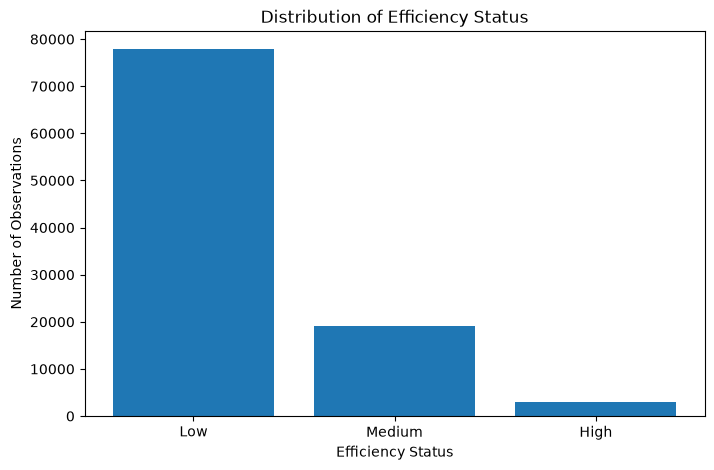

In [ ]:
# visualizing the distribution of the efficiency status, since from the previous cell we see that the dataset is imbalanced
class_counts = df["Efficiency_Status"].value_counts()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("Distribution of Efficiency Status")
plt.xlabel("Efficiency Status")
plt.ylabel("Number of Observations")

plt.show()

In [20]:
# Machine_ID has an int64 datatype, so Python sees it as a number.
# But conceptually it is not a numerical measurement.
# Numeric datatype ≠ Meaningful numerical feature
        
print("Number of unique machines:", df["Machine_ID"].nunique())
print("Minimum Machine ID:", df["Machine_ID"].min())
print("Maximum Machine ID:", df["Machine_ID"].max())

Number of unique machines: 50
Minimum Machine ID: 1
Maximum Machine ID: 50


In [22]:
# Convert and inspect the Timestamp column
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

print("Timestamp data type:", df["Timestamp"].dtype)
print("Start time:", df["Timestamp"].min())
print("End time:", df["Timestamp"].max())

Timestamp data type: datetime64[us]
Start time: 2024-01-01 00:00:00
End time: 2024-03-10 10:39:00


In [24]:
# check the time interval between observations
time_intervals = (
    df["Timestamp"]
    .sort_values()
    .diff()
    .value_counts()
)

print(time_intervals.head())

Timestamp
0 days 00:01:00    99999
Name: count, dtype: int64


##### observations are recorded roughly every 1 minute.
Why is this useful?
This tells us whether the data is sampled at a regular interval.
That matters because if observations are evenly spaced in time, then later we can reason about:
1. time based patterns
2. possible temporal dependence
3. whether random train test splitting is appropriate
4. whether we may want a time based split as an additional experiment

In [25]:
# correlation between features
numeric_features = [
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Quality_Control_Defect_Rate_%",
    "Production_Speed_units_per_hr",
    "Predictive_Maintenance_Score",
    "Error_Rate_%"
]

corr_matrix = df[numeric_features].corr()

corr_matrix

,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%
Temperature_C,1.000000,0.000610,0.004584,-0.002467,0.002861,-0.002238,0.001451,-0.002188,-0.001806
Vibration_Hz,0.000610,1.000000,0.005340,0.007546,0.000396,0.000357,-0.001335,0.003957,0.004579
Power_Consumption_kW,0.004584,0.005340,1.000000,-0.003245,-0.001198,-0.000918,0.001970,0.001627,0.000889
Network_Latency_ms,-0.002467,0.007546,-0.003245,1.000000,-0.006886,-0.004356,-0.001050,-0.002901,0.000098
Packet_Loss_%,0.002861,0.000396,-0.001198,-0.006886,1.000000,-0.004897,-0.007119,0.000756,-0.002406
Quality_Control_Defect_Rate_%,-0.002238,0.000357,-0.000918,-0.004356,-0.004897,1.000000,-0.004937,-0.000168,-0.001487
Production_Speed_units_per_hr,0.001451,-0.001335,0.001970,-0.001050,-0.007119,-0.004937,1.000000,0.003511,0.006070
Predictive_Maintenance_Score,-0.002188,0.003957,0.001627,-0.002901,0.000756,-0.000168,0.003511,1.000000,0.004525
Error_Rate_%,-0.001806,0.004579,0.000889,0.000098,-0.002406,-0.001487,0.006070,0.004525,1.000000


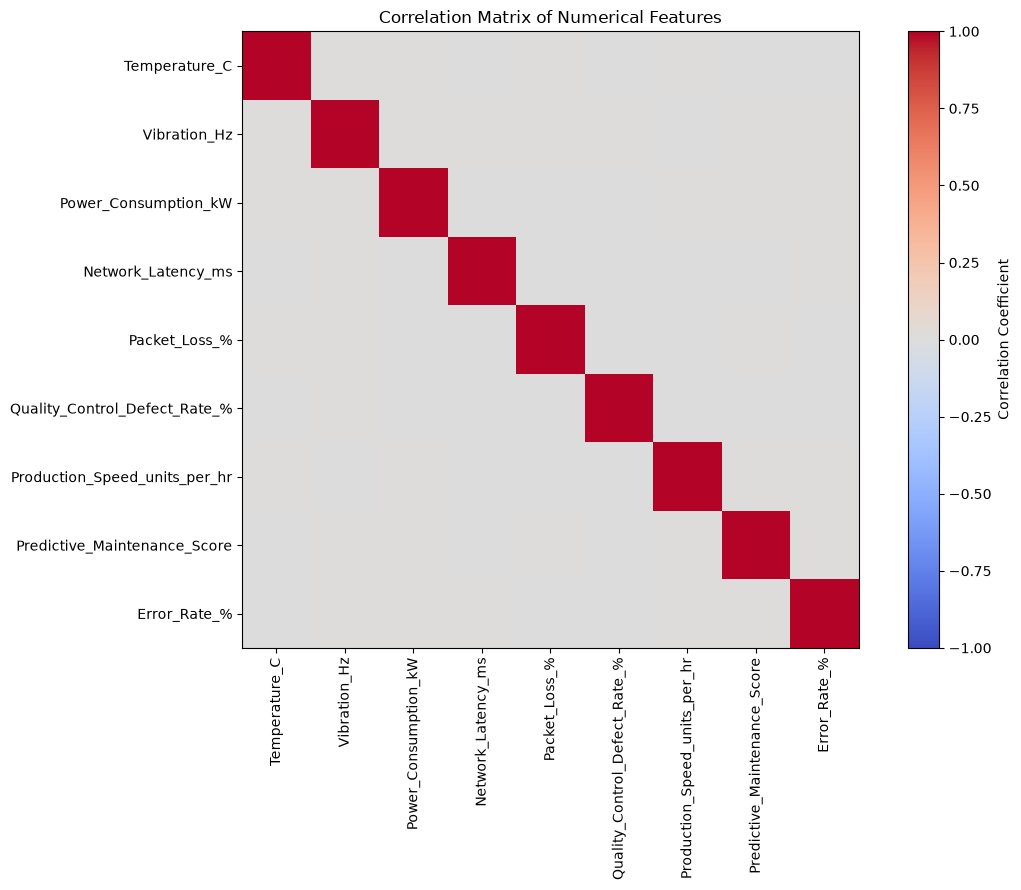

In [27]:
# Visualize the correlation matrix
plt.figure(figsize=(12, 9))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("Correlation Matrix of Numerical Features")

plt.tight_layout()
plt.show()

In [ ]:
# Compare mean numerical measurements across efficiency classes
class_means = (
    df.groupby("Efficiency_Status")[numeric_features]
    .mean()
    .round(3)
)

class_means

,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%
Efficiency_Status,,,,,,,,,
High,60.232,2.548,5.718,25.334,2.528,4.930,450.791,0.495,1.007
Low,60.006,2.550,5.743,25.562,2.494,5.017,254.854,0.500,8.930
Medium,60.154,2.552,5.762,25.566,2.487,4.989,334.125,0.498,2.733


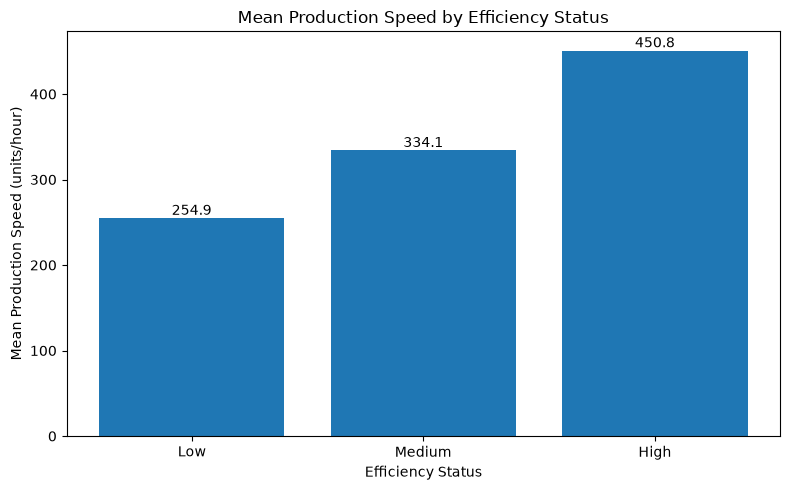

In [29]:
#Visualize mean Production Speed by Efficiency class
production_speed_means = (
    df.groupby("Efficiency_Status")[
        "Production_Speed_units_per_hr"
    ]
    .mean()
    .reindex(["Low", "Medium", "High"])
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    production_speed_means.index,
    production_speed_means.values
)

plt.title("Mean Production Speed by Efficiency Status")
plt.xlabel("Efficiency Status")
plt.ylabel("Mean Production Speed (units/hour)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.1f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

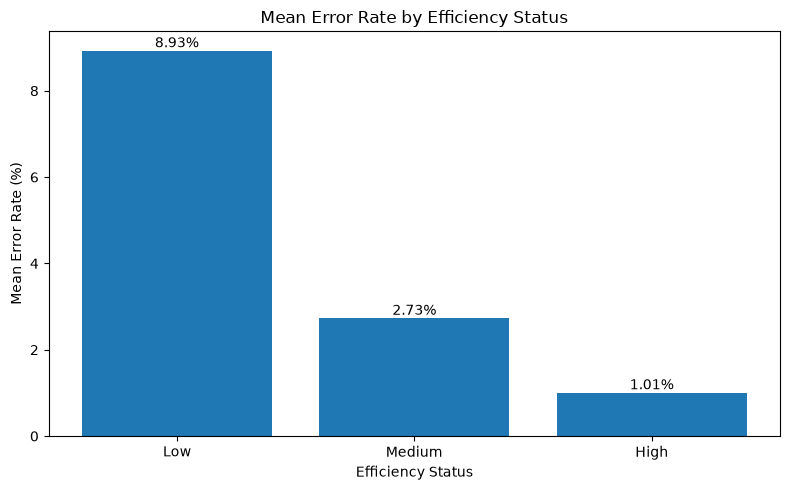

In [30]:
# Visualize mean Error Rate by Efficiency class
error_rate_means = (
    df.groupby("Efficiency_Status")[
        "Error_Rate_%"
    ]
    .mean()
    .reindex(["Low", "Medium", "High"])
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    error_rate_means.index,
    error_rate_means.values
)

plt.title("Mean Error Rate by Efficiency Status")
plt.xlabel("Efficiency Status")
plt.ylabel("Mean Error Rate (%)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [31]:
# Compare minimum, maximum and mean values
important_feature_ranges = (
    df.groupby("Efficiency_Status")[
        [
            "Production_Speed_units_per_hr",
            "Error_Rate_%"
        ]
    ]
    .agg(["min", "max", "mean"])
    .round(3)
)

important_feature_ranges

Production_Speed_units_per_hr                    \
                                            min      max     mean   
Efficiency_Status                                                   
High                                    400.122  499.981  450.791   
Low                                      50.000  499.997  254.854   
Medium                                  200.007  499.977  334.125   

                  Error_Rate_%               
                           min   max   mean  
Efficiency_Status                            
High                       0.0   2.0  1.007  
Low                        0.0  15.0  8.930  
Medium                     0.0   5.0  2.733

In [32]:
# Test whether Production Speed and Error Rate reproduce the target
def derive_efficiency_status(row):

    production_speed = row["Production_Speed_units_per_hr"]
    error_rate = row["Error_Rate_%"]

    if production_speed >= 400 and error_rate <= 2:
        return "High"

    elif production_speed >= 200 and error_rate <= 5:
        return "Medium"

    else:
        return "Low"


df["Derived_Efficiency_Status"] = df.apply(
    derive_efficiency_status,
    axis=1
)

df[
    [
        "Production_Speed_units_per_hr",
        "Error_Rate_%",
        "Efficiency_Status",
        "Derived_Efficiency_Status"
    ]
].head(10)

,Production_Speed_units_per_hr,Error_Rate_%,Efficiency_Status,Derived_Efficiency_Status
0,477.657391,14.965470,Low,Low
1,398.174747,7.678270,Low,Low
2,108.074959,8.198391,Low,Low
3,329.579410,2.740847,Medium,Medium
4,159.113525,12.100686,Low,Low
5,147.687703,0.040716,Low,Low
6,222.974691,9.032313,Low,Low
7,241.456735,0.738357,Medium,Medium
8,148.458144,11.446013,Low,Low
9,281.258013,3.687912,Medium,Medium


In [33]:
matches = (
    df["Efficiency_Status"]
    == df["Derived_Efficiency_Status"]
)

matching_rows = matches.sum()
total_rows = len(df)
match_percentage = matches.mean() * 100

print("Total rows:", total_rows)
print("Matching rows:", matching_rows)
print("Non matching rows:", total_rows - matching_rows)
print("Match percentage:", round(match_percentage, 2), "%")

Total rows: 100000
Matching rows: 100000
Non matching rows: 0
Match percentage: 100.0 %


In [34]:
df.drop(
    columns=["Derived_Efficiency_Status"],
    inplace=True
)

In [35]:
print(df.columns)

Index(['Timestamp', 'Machine_ID', 'Operation_Mode', 'Temperature_C',
       'Vibration_Hz', 'Power_Consumption_kW', 'Network_Latency_ms',
       'Packet_Loss_%', 'Quality_Control_Defect_Rate_%',
       'Production_Speed_units_per_hr', 'Predictive_Maintenance_Score',
       'Error_Rate_%', 'Efficiency_Status'],
      dtype='str')


# Dataset Understanding and Problem Definition

## Dataset Overview

The dataset contains:

**100,000 observations**

**13 attributes**

The dataset represents manufacturing related operational, sensor, network, production, maintenance, and efficiency information.

## Data Quality

The dataset was inspected for missing values and duplicate records.

**Missing values:** 0

**Duplicate rows:** 0

Therefore, no missing value imputation or duplicate removal is required at this stage.

## Target Variable

The target variable selected for the project is:

`Efficiency_Status`

It contains three classes:

`Low`

`Medium`

`High`

Therefore, this is a **supervised multiclass classification problem**.

## Target Class Distribution

The target classes are not equally distributed.

Approximate class distribution:

`Low` ≈ 77.8%

`Medium` ≈ 19.2%

`High` ≈ 3.0%

This indicates a clear **class imbalance**.

Because of this imbalance, model performance should not be evaluated using accuracy alone.

Later evaluation should also consider:

`Precision`

`Recall`

`F1 Score`

`Macro F1 Score`

`Confusion Matrix`

## Machine ID

The dataset contains **50 unique machines**.

`Machine_ID` is stored as a numerical value, but it is an identifier rather than a physical measurement.

For example, Machine 20 is not numerically twice Machine 10.

Therefore, `Machine_ID` will not initially be treated as a normal numerical input feature.

## Timestamp

The `Timestamp` column was converted from text to datetime format.

The dataset contains observations recorded at approximately **one minute intervals**.

The raw timestamp will not initially be used as a model input feature.

If necessary, time based features such as hour, day, or day of week could be created later.

## Numerical Feature Correlation

A correlation matrix was calculated for the numerical manufacturing features.

Most numerical features showed very weak pairwise linear correlations.

This suggests that the numerical measurements are not strongly linearly related to each other.

However, correlation between input features does not directly indicate how useful a feature is for predicting the categorical target.

## Feature Values Across Efficiency Classes

The numerical features were grouped by `Efficiency_Status`, and their mean values were compared across the three classes.

Two features showed particularly strong differences.

### Production Speed

Approximate mean production speed:

`Low` ≈ 254.9 units/hour

`Medium` ≈ 334.1 units/hour

`High` ≈ 450.8 units/hour

Production speed increases clearly from Low to High efficiency.

### Error Rate

Approximate mean error rate:

`Low` ≈ 8.93%

`Medium` ≈ 2.73%

`High` ≈ 1.01%

Error rate decreases clearly from Low to High efficiency.

Other features such as temperature and vibration showed much smaller differences in their class means.

## Efficiency Status Rule Investigation

Further analysis of Production Speed and Error Rate revealed clear threshold patterns.

The following rule was tested:

```text
If Production Speed >= 400 and Error Rate <= 2
    High

Else if Production Speed >= 200 and Error Rate <= 5
    Medium

Else
    Low
```

The derived labels were compared with the original `Efficiency_Status` labels.

**Result**

**100,000 out of 100,000 rows matched**

**Match percentage = 100%**

This indicates that the `Efficiency_Status` target can be perfectly reconstructed using threshold conditions based on Production Speed and Error Rate.

This does **not** prove that these two variables cause manufacturing efficiency.

It shows that, within this dataset, the target labels follow a deterministic relationship involving these two features.

## Initial Feature Selection

The following columns will initially be excluded from normal model input:

`Timestamp`

`Machine_ID`

The target variable is:

`Efficiency_Status`

The remaining operational, sensor, production, network, maintenance, and quality related variables will be considered as candidate input features.

## Conclusion

The dataset is suitable for a supervised multiclass classification project.

The main prediction objective is to classify manufacturing observations into:

`Low`

`Medium`

`High`

efficiency categories.

The dataset has a strong class imbalance, which must be considered during model evaluation.

Initial analysis also revealed that Production Speed and Error Rate are strongly associated with the target classes, and together they can reproduce the existing efficiency labels exactly.

This finding will be investigated further during model training, feature importance analysis, and later feature removal experiments.